# One interesting thing: wine types have different review language and ratings

This notebook is a standalone descriptive analysis for a five-minute presentation. It compares **red, white, rosé, sparkling, and dessert** wines using review text and `points`. The heterogeneous `other` category is excluded. No predictive models are used.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

wine_types = ['red', 'white', 'rose', 'sparkling', 'dessert']
palette = ['#9f2d3f', '#d4a946', '#df8c9b', '#81a8bb', '#8d669c']
wine = pd.read_parquet(
    'df_with_color.parquet',
    columns=['color', 'description', 'points', 'price', 'taster_name'],
)
wine = wine.loc[wine['color'].isin(wine_types)].copy()
print(f'{len(wine):,} reviews across the five wine types')

169,177 reviews across the five wine types


## 1. How much data is in each group?

The groups are very uneven, so always show the sample size next to a percentage or average. Red and white dominate the dataset; dessert wine has the fewest reviews.

In [2]:
group_sizes = wine['color'].value_counts().reindex(wine_types)
group_summary = pd.DataFrame({
    'reviews': group_sizes,
    'share_of_five_types_pct': 100 * group_sizes / len(wine),
})
group_summary.round(2)

,reviews,share_of_five_types_pct
color,,
red,103819,61.37
white,54251,32.07
rose,4118,2.43
sparkling,5536,3.27
dessert,1453,0.86


## 2. Flavor and texture language

The next table gives the **percentage of reviews mentioning each whole word at least once**. This avoids counting repeated use of a word within one review as multiple observations. The words were selected to illustrate sensory differences; they were not selected by a prediction model. Some words appear in more than one type, which is part of the story.

In [3]:
sensory_words = [
    'tannins', 'cherry', 'apple', 'citrus', 'strawberry',
    'watermelon', 'bubbles', 'yeasty', 'toffee', 'caramel',
]
word_present = pd.DataFrame({
    word: wine['description'].fillna('').str.contains(
        rf'\b{re.escape(word)}\b', case=False, regex=True
    )
    for word in sensory_words
}, index=wine.index)
word_prevalence_pct = (
    word_present.groupby(wine['color']).mean().mul(100)
    .T.reindex(columns=wine_types)
)
word_prevalence_pct.round(1)

color,red,white,rose,sparkling,dessert
tannins,35.8,0.4,1.7,0.8,23.5
cherry,32.8,0.4,17.3,4.7,4.4
apple,0.6,23.0,4.1,26.6,1.1
citrus,1.0,21.8,10.9,17.7,3.0
strawberry,3.5,0.1,20.7,6.8,1.0
watermelon,0.2,0.1,5.6,0.3,0.0
bubbles,0.0,0.4,0.1,6.1,0.2
yeasty,0.1,1.0,0.6,7.5,0.3
toffee,0.2,0.3,0.0,0.1,5.7
caramel,1.3,2.5,6.7,1.2,8.2


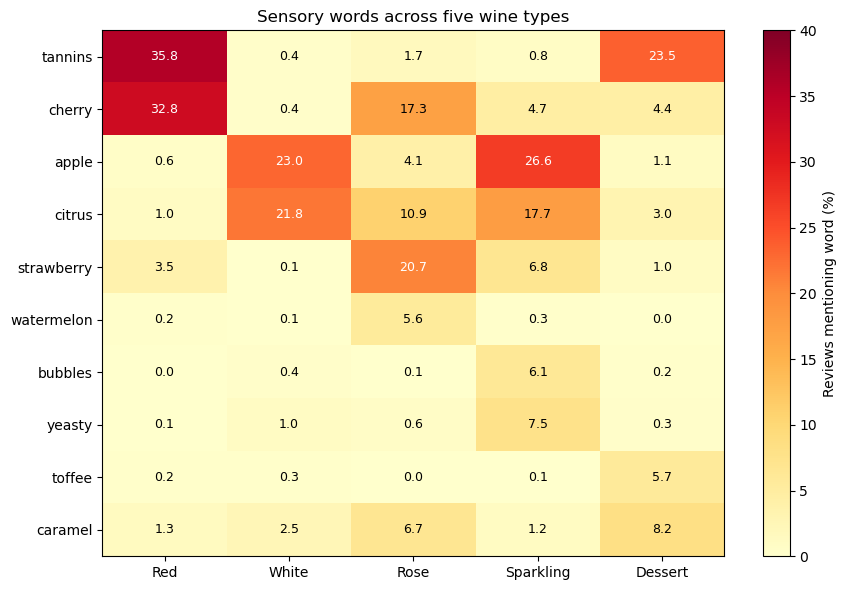

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
heatmap = ax.imshow(word_prevalence_pct.to_numpy(), cmap='YlOrRd', vmin=0, vmax=40, aspect='auto')
ax.set_xticks(range(len(wine_types)), labels=[name.title() for name in wine_types])
ax.set_yticks(range(len(sensory_words)), labels=sensory_words)
for row in range(len(sensory_words)):
    for col in range(len(wine_types)):
        value = word_prevalence_pct.iat[row, col]
        ax.text(col, row, f'{value:.1f}', ha='center', va='center',
                color='white' if value >= 20 else 'black', fontsize=9)
fig.colorbar(heatmap, ax=ax, label='Reviews mentioning word (%)')
ax.set_title('Sensory words across five wine types')
plt.tight_layout()
plt.show()

**What to notice:** “Tannins” and “cherry” are common in red reviews, but dessert wines also often mention “tannins.” Rosé has a strong “strawberry” signal. Sparkling shares “apple” and “citrus” language with white wine, while “bubbles” and “yeasty” are more specific to sparkling. Dessert reviews stand out for “toffee” and “caramel.” These are associations in the reviews, not exclusive definitions of the wine types.

## 3. Review length

Count alphabetic words in each description. Punctuation and numbers are excluded; a one-letter word still counts. This provides another simple comparison of how reviewers write about the five types.

In [5]:
word_pattern = re.compile(r'(?u)\b[^\W\d_]+\b')
wine['review_word_count'] = wine['description'].fillna('').map(
    lambda text: len(word_pattern.findall(text))
)
length_summary = wine.groupby('color')['review_word_count'].agg(
    reviews='size', mean_words='mean', median_words='median'
).reindex(wine_types)
length_summary.round(2)

,reviews,mean_words,median_words
color,,,
red,103819,42.27,42.0
white,54251,39.35,38.0
rose,4118,36.46,35.0
sparkling,5536,40.73,40.0
dessert,1453,39.14,38.0


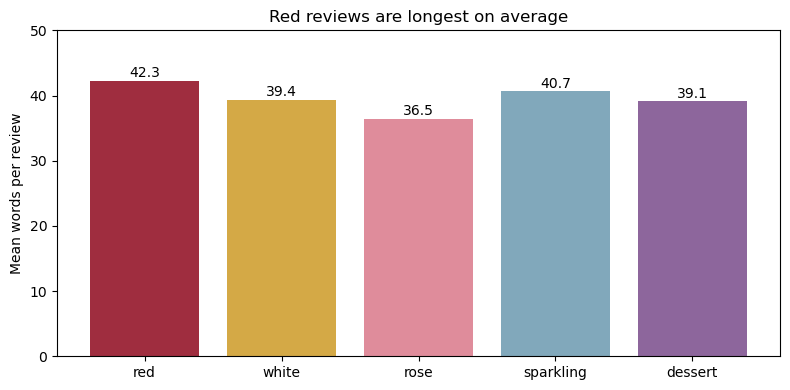

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(wine_types, length_summary['mean_words'], color=palette)
ax.set_ylim(0, 50)
ax.set_ylabel('Mean words per review')
ax.set_title('Red reviews are longest on average')
for i, value in enumerate(length_summary['mean_words']):
    ax.text(i, value + 0.5, f'{value:.1f}', ha='center')
plt.tight_layout()
plt.show()

## 4. Ratings: a smaller difference than the language suggests

Compare mean, median, spread, and the share scoring 95 or higher. All five types have overlapping score distributions, and group sizes differ greatly. Median price is included as context; prices are missing for some wines. The rating comparison is descriptive and does not establish that one wine type is inherently better.

In [7]:
rating_summary = wine.groupby('color').agg(
    reviews=('points', 'size'),
    mean_points=('points', 'mean'),
    median_points=('points', 'median'),
    sd_points=('points', 'std'),
    pct_95_plus=('points', lambda values: 100 * values.ge(95).mean()),
    median_price=('price', 'median'),
).reindex(wine_types)
rating_summary.round(2)

,reviews,mean_points,median_points,sd_points,pct_95_plus,median_price
color,,,,,,
red,103819,88.46,88.0,3.20,2.18,30.0
white,54251,87.94,88.0,3.01,1.55,20.0
rose,4118,86.65,87.0,2.57,0.05,16.0
sparkling,5536,88.13,88.0,3.12,2.29,26.5
dessert,1453,88.96,89.0,3.29,5.57,30.0


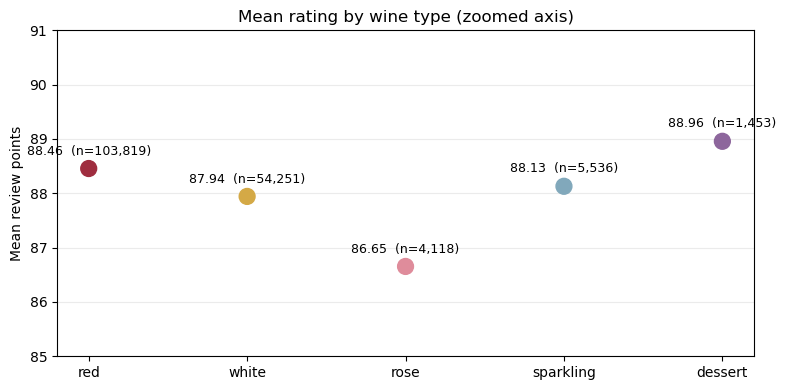

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(wine_types, rating_summary['mean_points'], c=palette, s=130, zorder=3)
for wine_type, row in rating_summary.iterrows():
    ax.annotate(
        f"{row['mean_points']:.2f}  (n={int(row['reviews']):,})",
        (wine_type, row['mean_points']), xytext=(0, 10),
        textcoords='offset points', ha='center', fontsize=9,
    )
ax.set_ylim(85, 91)
ax.set_ylabel('Mean review points')
ax.set_title('Mean rating by wine type (zoomed axis)')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

**What to notice:** Red and white mean scores differ by about half a point, while both have a median of 88. Dessert has the highest mean and rosé the lowest in this sample, but their groups are much smaller. Reviewer assignments, price, region, and the wines selected for review may all affect these comparisons.

## Five-minute presentation path

1. **Set up (40 seconds):** Introduce the five types and their uneven sample sizes.
2. **Language (90 seconds):** Walk through the heatmap, including the surprising overlaps (sparkling with white; dessert with red).
3. **Review length (40 seconds):** Show that red reviews are a few words longer on average.
4. **Ratings (90 seconds):** Contrast the large language differences with the relatively small score differences; point out medians and sample sizes.
5. **Interpretation (60 seconds):** Explain why these are patterns in a reviewed sample, not a ranking of wine quality. Ask whether the score differences would persist among similarly priced wines reviewed by the same people.